In [2]:
import os
import pandas as pd

# ============================================================
# Paths
# ============================================================
META_FILE = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/End_motif/metastasis_site_summary/metastasis_single_site_one_per_bios_site.csv"
OUTDIR = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/CNV_Profiles/metastasis_single_site_one_per_bios_site"
OUTFILE = os.path.join(OUTDIR, "all_single_site_counts.tsv")

os.makedirs(OUTDIR, exist_ok=True)

# ============================================================
# Load metadata
# ============================================================
meta = pd.read_csv(META_FILE)

# Clean columns
meta["id"] = meta["id"].astype(str).str.strip()
meta["metastatic_sites"] = meta["metastatic_sites"].astype(str).str.strip().str.lower()

# Remove missing / empty values if any
meta = meta[
    meta["id"].notna() &
    meta["metastatic_sites"].notna() &
    (meta["metastatic_sites"] != "") &
    (meta["metastatic_sites"] != "nan")
].copy()

# ============================================================
# Count samples per single metastatic site
# ============================================================
site_counts = (
    meta["metastatic_sites"]
    .value_counts()
    .rename_axis("site")
    .reset_index(name="n_samples")
)

# ============================================================
# Print result
# ============================================================
print("\nAll single metastatic site counts:\n")
print(site_counts.to_string(index=False))

# ============================================================
# Save result
# ============================================================
site_counts.to_csv(OUTFILE, sep="\t", index=False)

print(f"\nSaved: {OUTFILE}")


All single metastatic site counts:

                      site  n_samples
                     liver         24
                      bone         14
                     brain         12
                        ln          7
                      lung          5
                     spine          3
                    breast          3
                chest wall          3
          pleural effusion          2
                    pleura          2
                     skull          1
                   omentum          1
contralateral right axilla          1
                    kidney          1
                recurrence          1

Saved: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/CNV_Profiles/metastasis_single_site_one_per_bios_site/all_single_site_counts.tsv


Samples found in wide matrix and metadata: 50

Sample counts by site:
liver: 24
brain: 12
bone: 14


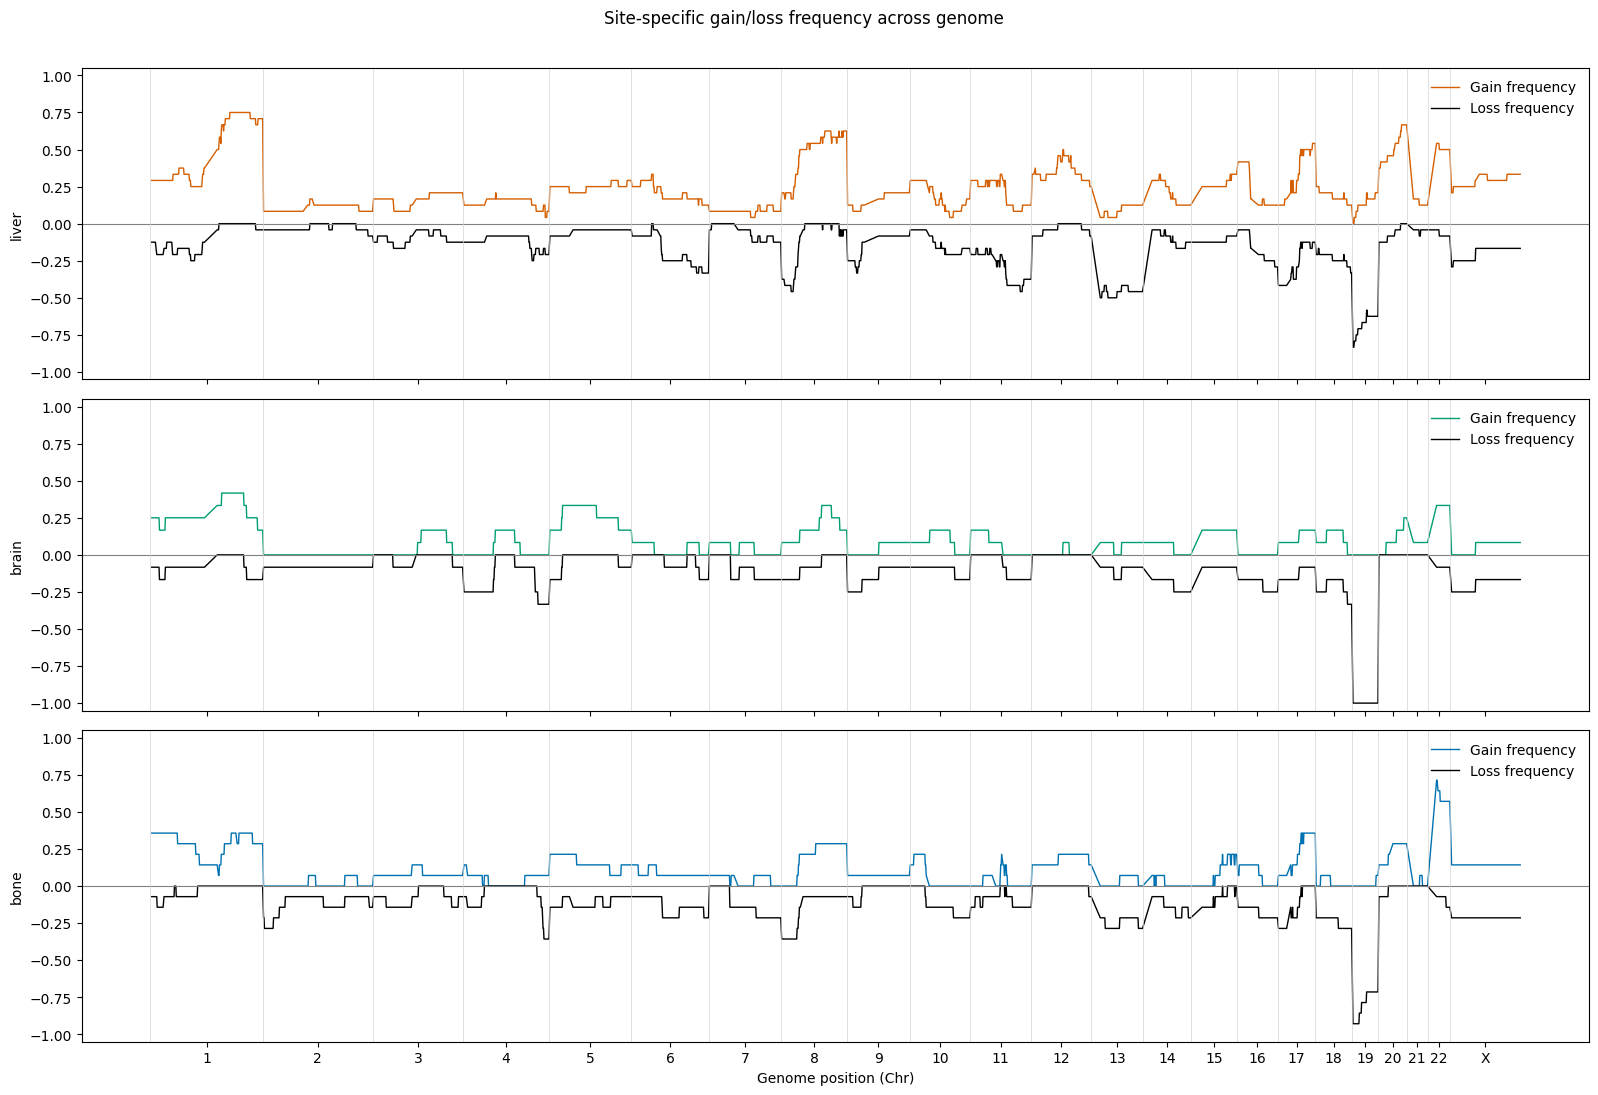


Saved files:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/CNV_Profiles/metastasis_single_site_one_per_bios_site/site_gain_loss_frequency_across_genome.tsv
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/CNV_Profiles/metastasis_single_site_one_per_bios_site/site_gain_loss_frequency_across_genome.png
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/CNV_Profiles/metastasis_single_site_one_per_bios_site/site_gain_loss_frequency_across_genome.pdf


In [3]:
# Genome wide CNV profile
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# Paths
# ============================================================
WIDE_FILE = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/CNV_Profiles/combined_top3sites_1Mb_cnr_wide.tsv"
META_FILE = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/End_motif/metastasis_site_summary/metastasis_single_site_one_per_bios_site.csv"
OUTDIR = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/CNV_Profiles/metastasis_single_site_one_per_bios_site"

os.makedirs(OUTDIR, exist_ok=True)

OUT_PNG = os.path.join(OUTDIR, "site_gain_loss_frequency_across_genome.png")
OUT_PDF = os.path.join(OUTDIR, "site_gain_loss_frequency_across_genome.pdf")

# Optional summary table
OUT_TSV = os.path.join(OUTDIR, "site_gain_loss_frequency_across_genome.tsv")

# ============================================================
# Settings
# ============================================================
FOCUS_SITES = ["liver", "brain", "bone"]
SITE_ORDER = ["liver", "brain", "bone"]

SITE_COLORS = {
    "liver": "#D55E00",
    "brain": "#009E73",
    "bone":  "#0072B2"
}

CHR_ORDER = [f"chr{i}" for i in range(1, 23)] + ["chrX", "chrY"]

# ============================================================
# Helper functions
# ============================================================
def parse_samples_from_wide(df):
    log2_cols = [c for c in df.columns if c.endswith(".log2")]
    return sorted([c[:-5] for c in log2_cols])  # remove ".log2"

def clean_call(x):
    if pd.isna(x):
        return np.nan

    x = str(x).strip().upper()

    # Gains
    if x in {"GAIN", "AMP", "HLAMP", "AMPLIFICATION"}:
        return "GAIN"

    # Losses / deletions
    if x in {"LOSS", "DEL", "HETD", "HOMD", "DELETION"}:
        return "LOSS"

    # Neutral
    if x in {"NEUT", "NEUTRAL"}:
        return "NEUTRAL"

    return x

def chromosome_sort_key(chrom):
    return CHR_ORDER.index(chrom) if chrom in CHR_ORDER else 999

# ============================================================
# Load files
# ============================================================
wide = pd.read_csv(WIDE_FILE, sep="\t")
meta = pd.read_csv(META_FILE)

meta["id"] = meta["id"].astype(str).str.strip()
meta["metastatic_sites"] = meta["metastatic_sites"].astype(str).str.strip().str.lower()
meta = meta[meta["metastatic_sites"].isin(FOCUS_SITES)].copy()

sample_to_site = dict(zip(meta["id"], meta["metastatic_sites"]))

samples = parse_samples_from_wide(wide)
samples = [s for s in samples if s in sample_to_site]

print("Samples found in wide matrix and metadata:", len(samples))
print("\nSample counts by site:")
for site in SITE_ORDER:
    n = sum(sample_to_site[s] == site for s in samples)
    print(f"{site}: {n}")

# ============================================================
# Prepare genomic coordinate table
# ============================================================
plot_df = wide[["chromosome", "start", "end", "gene"]].copy()
plot_df["chromosome"] = plot_df["chromosome"].astype(str)
plot_df["start"] = pd.to_numeric(plot_df["start"], errors="coerce")
plot_df["end"] = pd.to_numeric(plot_df["end"], errors="coerce")

plot_df = plot_df.dropna(subset=["chromosome", "start", "end"]).copy()
plot_df["start"] = plot_df["start"].astype(int)
plot_df["end"] = plot_df["end"].astype(int)

plot_df = plot_df[plot_df["chromosome"].isin(CHR_ORDER)].copy()
plot_df["chr_order"] = plot_df["chromosome"].map(chromosome_sort_key)
plot_df = plot_df.sort_values(["chr_order", "start", "end"]).reset_index(drop=True)

# midpoint within chromosome
plot_df["midpoint"] = (plot_df["start"] + plot_df["end"]) / 2.0

# ============================================================
# Compute gain/loss frequency per site for each bin
# ============================================================
for site in SITE_ORDER:
    site_samples = [s for s in samples if sample_to_site[s] == site]

    if len(site_samples) == 0:
        plot_df[f"{site}_gain_freq"] = np.nan
        plot_df[f"{site}_loss_freq"] = np.nan
        plot_df[f"{site}_n_valid"] = 0
        continue

    collapsed_calls = []
    for sample in site_samples:
        call_col = f"{sample}.Corrected_Call"
        if call_col not in wide.columns:
            continue
        collapsed_calls.append(wide[call_col].apply(clean_call).rename(sample))

    if len(collapsed_calls) == 0:
        plot_df[f"{site}_gain_freq"] = np.nan
        plot_df[f"{site}_loss_freq"] = np.nan
        plot_df[f"{site}_n_valid"] = 0
        continue

    site_call_df = pd.concat(collapsed_calls, axis=1)

    valid_counts = site_call_df.notna().sum(axis=1)
    gain_counts = (site_call_df == "GAIN").sum(axis=1)
    loss_counts = (site_call_df == "LOSS").sum(axis=1)

    gain_freq = np.where(valid_counts > 0, gain_counts / valid_counts, np.nan)
    loss_freq = np.where(valid_counts > 0, loss_counts / valid_counts, np.nan)

    plot_df[f"{site}_gain_freq"] = gain_freq
    plot_df[f"{site}_loss_freq"] = loss_freq
    plot_df[f"{site}_n_valid"] = valid_counts.values

# Save summary table
plot_df.to_csv(OUT_TSV, sep="\t", index=False)

# ============================================================
# Build genome-wide x coordinates
# ============================================================
chrom_lengths = (
    plot_df.groupby("chromosome", as_index=False)["end"]
    .max()
    .sort_values("chromosome", key=lambda x: x.map(chromosome_sort_key))
)

chrom_offsets = {}
chrom_midpoints = {}
offset = 0

for _, row in chrom_lengths.iterrows():
    chrom = row["chromosome"]
    length = int(row["end"])
    chrom_offsets[chrom] = offset
    chrom_midpoints[chrom] = offset + (length / 2.0)
    offset += length

plot_df["genome_x"] = plot_df.apply(
    lambda r: chrom_offsets[r["chromosome"]] + r["midpoint"],
    axis=1
)

# ============================================================
# Plot
# ============================================================
fig, axes = plt.subplots(len(SITE_ORDER), 1, figsize=(16, 3.6 * len(SITE_ORDER)), sharex=True)

if len(SITE_ORDER) == 1:
    axes = [axes]

for ax, site in zip(axes, SITE_ORDER):
    gain_col = f"{site}_gain_freq"
    loss_col = f"{site}_loss_freq"

    ax.plot(
        plot_df["genome_x"],
        plot_df[gain_col],
        linewidth=1.0,
        color=SITE_COLORS[site],
        label="Gain frequency"
    )

    ax.plot(
        plot_df["genome_x"],
        -plot_df[loss_col],
        linewidth=1.0,
        color="black",
        label="Loss frequency"
    )

    ax.axhline(0, color="grey", linewidth=0.8)

    for chrom, start_offset in chrom_offsets.items():
        ax.axvline(start_offset, color="lightgrey", linewidth=0.5)

    ax.set_ylim(-1.05, 1.05)
    ax.set_ylabel(site)
    ax.legend(frameon=False, loc="upper right")

axes[-1].set_xticks([chrom_midpoints[c] for c in chrom_lengths["chromosome"]])
axes[-1].set_xticklabels([c.replace("chr", "") for c in chrom_lengths["chromosome"]], rotation=0)
axes[-1].set_xlabel("Genome position (Chr)")

fig.suptitle("Site-specific gain/loss frequency across genome", y=1.01)

plt.tight_layout()
plt.savefig(OUT_PNG, dpi=300, bbox_inches="tight")
plt.savefig(OUT_PDF, bbox_inches="tight")
plt.show()
plt.close()

print("\nSaved files:")
print(OUT_TSV)
print(OUT_PNG)
print(OUT_PDF)

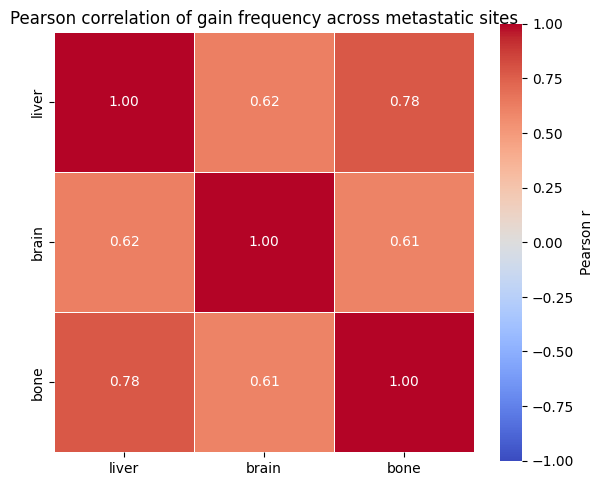

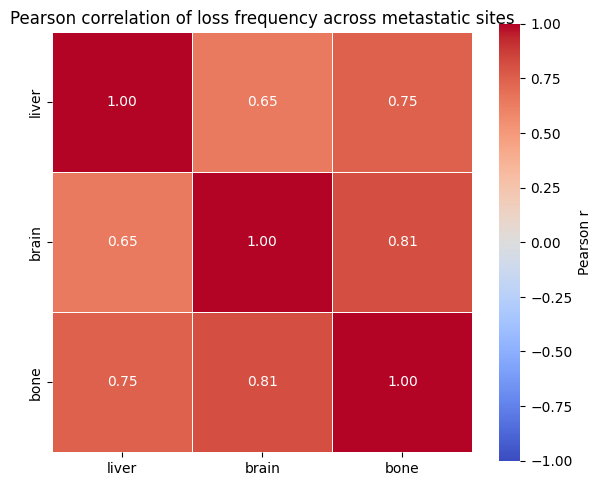


Pearson correlation outputs:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/CNV_Profiles/metastasis_single_site_one_per_bios_site/Pearson_correlation/gain_frequency_pearson_correlation.tsv
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/CNV_Profiles/metastasis_single_site_one_per_bios_site/Pearson_correlation/gain_frequency_pearson_pvalues.tsv
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/CNV_Profiles/metastasis_single_site_one_per_bios_site/Pearson_correlation/gain_frequency_pearson_heatmap.png
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/CNV_Profiles/metastasis_single_site_one_per_bios_site/Pearson_correlation/gain_frequency_pearson_heatmap.pdf
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/CNV_Profiles/metastasis_single_site_one_per_bios_site/Pearson_correlation/loss_frequency_pearson_correlation.tsv
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/CNV_Profiles/metastasis_single_site_one_per_bios_site/Pearson_correlation/loss_fr

In [6]:
plot_df.to_csv(OUT_TSV, sep="\t", index=False)
# ============================================================
# Pearson correlation of gain/loss frequency across sites
# ============================================================
from scipy.stats import pearsonr
import seaborn as sns

CORR_OUTDIR = os.path.join(OUTDIR, "Pearson_correlation")
os.makedirs(CORR_OUTDIR, exist_ok=True)

GAIN_CORR_TSV = os.path.join(CORR_OUTDIR, "gain_frequency_pearson_correlation.tsv")
LOSS_CORR_TSV = os.path.join(CORR_OUTDIR, "loss_frequency_pearson_correlation.tsv")

GAIN_PVAL_TSV = os.path.join(CORR_OUTDIR, "gain_frequency_pearson_pvalues.tsv")
LOSS_PVAL_TSV = os.path.join(CORR_OUTDIR, "loss_frequency_pearson_pvalues.tsv")

GAIN_HEATMAP_PNG = os.path.join(CORR_OUTDIR, "gain_frequency_pearson_heatmap.png")
GAIN_HEATMAP_PDF = os.path.join(CORR_OUTDIR, "gain_frequency_pearson_heatmap.pdf")

LOSS_HEATMAP_PNG = os.path.join(CORR_OUTDIR, "loss_frequency_pearson_heatmap.png")
LOSS_HEATMAP_PDF = os.path.join(CORR_OUTDIR, "loss_frequency_pearson_heatmap.pdf")


def pairwise_pearson_matrix(df, cols):
    """
    Compute pairwise Pearson correlation and p-values
    using pairwise complete observations.
    """
    corr_mat = pd.DataFrame(index=cols, columns=cols, dtype=float)
    pval_mat = pd.DataFrame(index=cols, columns=cols, dtype=float)

    for c1 in cols:
        for c2 in cols:
            # diagonal
            if c1 == c2:
                corr_mat.loc[c1, c2] = 1.0
                pval_mat.loc[c1, c2] = 0.0
                continue

            sub = df[[c1, c2]].dropna()

            if len(sub) < 3:
                corr_mat.loc[c1, c2] = np.nan
                pval_mat.loc[c1, c2] = np.nan
            else:
                x = sub[c1].values
                y = sub[c2].values
                r, p = pearsonr(x, y)
                corr_mat.loc[c1, c2] = r
                pval_mat.loc[c1, c2] = p

    return corr_mat, pval_mat
# -----------------------------
# Gain frequency correlation
# -----------------------------
gain_cols = [f"{site}_gain_freq" for site in SITE_ORDER]
gain_df = plot_df[["chromosome", "start", "end"] + gain_cols].copy()

gain_corr, gain_pval = pairwise_pearson_matrix(gain_df, gain_cols)

# cleaner row/column names
gain_corr.index = SITE_ORDER
gain_corr.columns = SITE_ORDER
gain_pval.index = SITE_ORDER
gain_pval.columns = SITE_ORDER

gain_corr.to_csv(GAIN_CORR_TSV, sep="\t")
gain_pval.to_csv(GAIN_PVAL_TSV, sep="\t")

plt.figure(figsize=(6, 5))
sns.heatmap(
    gain_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5,
    cbar_kws={"label": "Pearson r"}
)
plt.title("Pearson correlation of gain frequency across metastatic sites")
plt.tight_layout()
plt.savefig(GAIN_HEATMAP_PNG, dpi=300, bbox_inches="tight")
plt.savefig(GAIN_HEATMAP_PDF, bbox_inches="tight")
plt.show()
plt.close()


# -----------------------------
# Loss frequency correlation
# -----------------------------
loss_cols = [f"{site}_loss_freq" for site in SITE_ORDER]
loss_df = plot_df[["chromosome", "start", "end"] + loss_cols].copy()

loss_corr, loss_pval = pairwise_pearson_matrix(loss_df, loss_cols)

loss_corr.index = SITE_ORDER
loss_corr.columns = SITE_ORDER
loss_pval.index = SITE_ORDER
loss_pval.columns = SITE_ORDER

loss_corr.to_csv(LOSS_CORR_TSV, sep="\t")
loss_pval.to_csv(LOSS_PVAL_TSV, sep="\t")

plt.figure(figsize=(6, 5))
sns.heatmap(
    loss_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5,
    cbar_kws={"label": "Pearson r"}
)
plt.title("Pearson correlation of loss frequency across metastatic sites")
plt.tight_layout()
plt.savefig(LOSS_HEATMAP_PNG, dpi=300, bbox_inches="tight")
plt.savefig(LOSS_HEATMAP_PDF, bbox_inches="tight")
plt.show()
plt.close()

print("\nPearson correlation outputs:")
print(GAIN_CORR_TSV)
print(GAIN_PVAL_TSV)
print(GAIN_HEATMAP_PNG)
print(GAIN_HEATMAP_PDF)
print(LOSS_CORR_TSV)
print(LOSS_PVAL_TSV)
print(LOSS_HEATMAP_PNG)
print(LOSS_HEATMAP_PDF)

/ihome/alee/rak373/.conda/envs/RegionalFragmentAnalysis/lib/python3.7/site-packages/ipykernel_launcher.py:164: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all axes decorations.


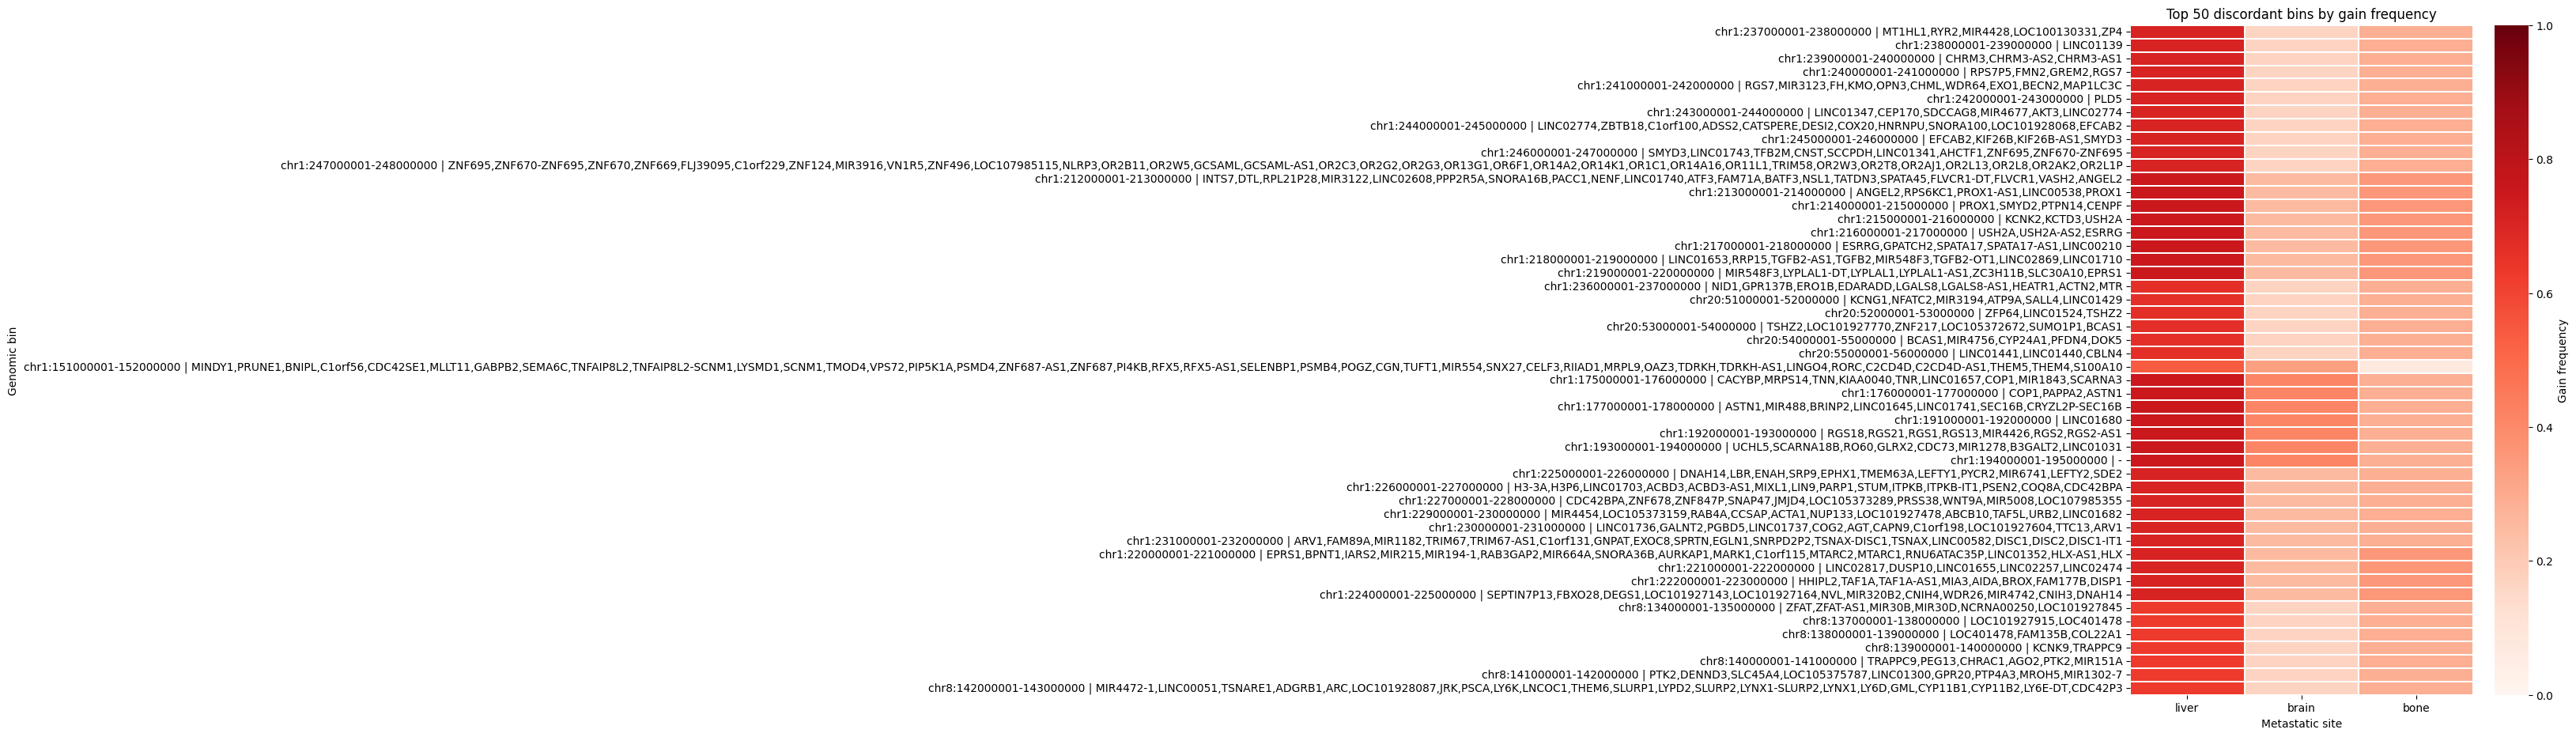

/ihome/alee/rak373/.conda/envs/RegionalFragmentAnalysis/lib/python3.7/site-packages/ipykernel_launcher.py:164: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all axes decorations.


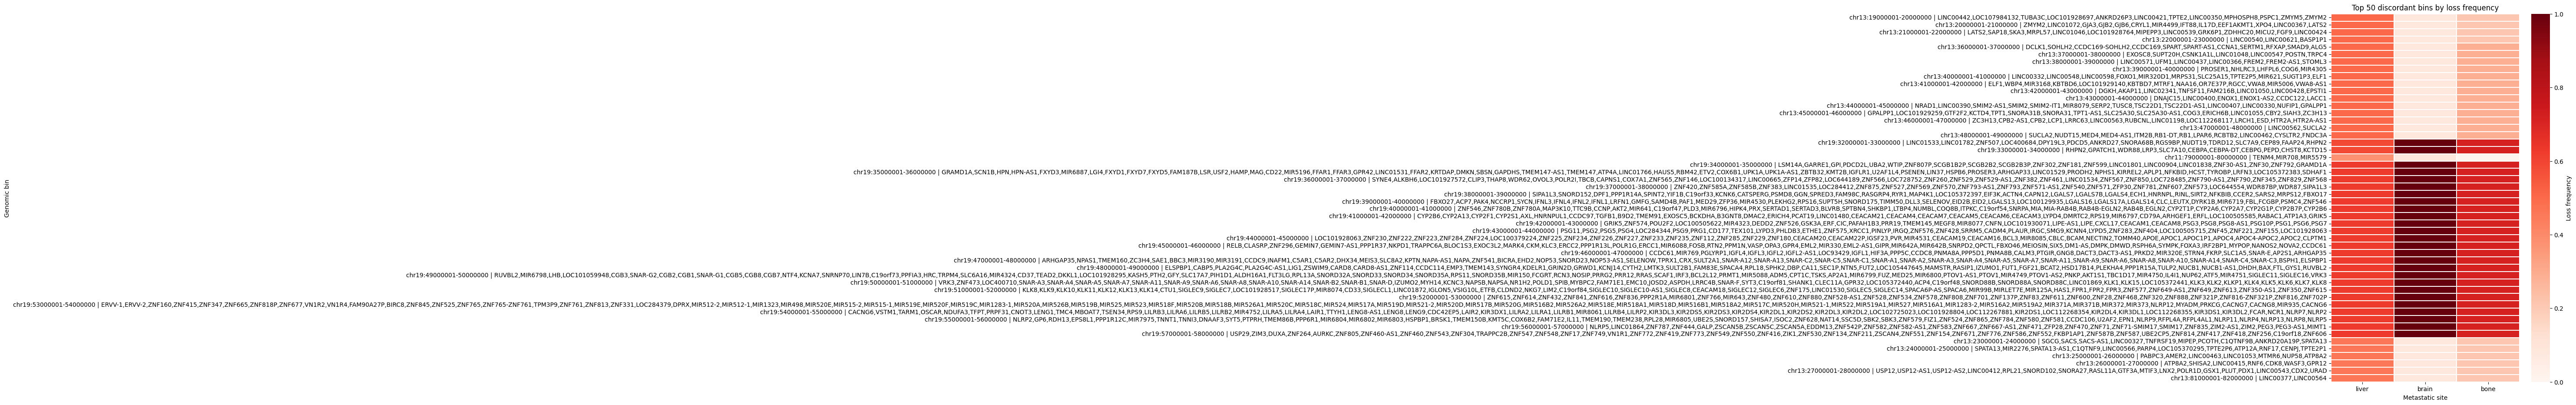

/ihome/alee/rak373/.conda/envs/RegionalFragmentAnalysis/lib/python3.7/site-packages/ipykernel_launcher.py:164: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all axes decorations.


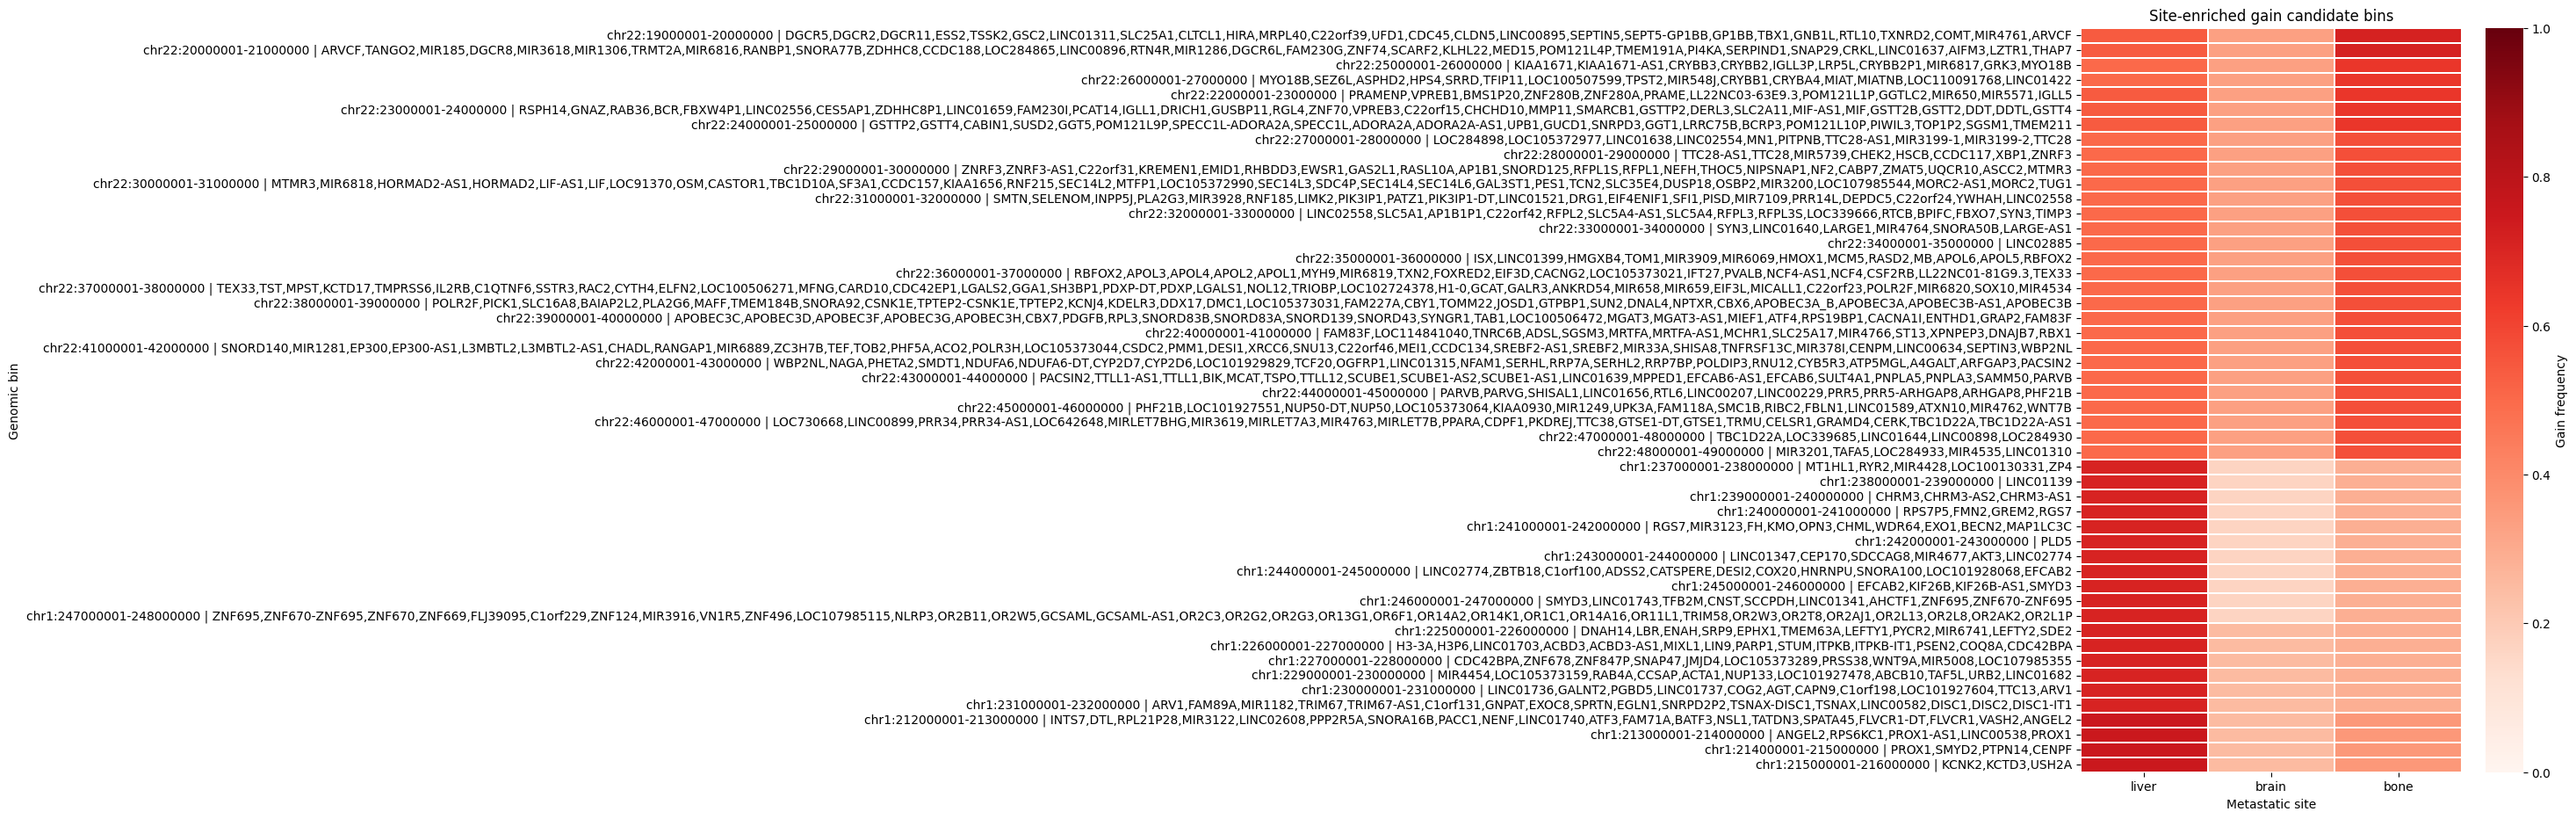

/ihome/alee/rak373/.conda/envs/RegionalFragmentAnalysis/lib/python3.7/site-packages/ipykernel_launcher.py:164: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all axes decorations.


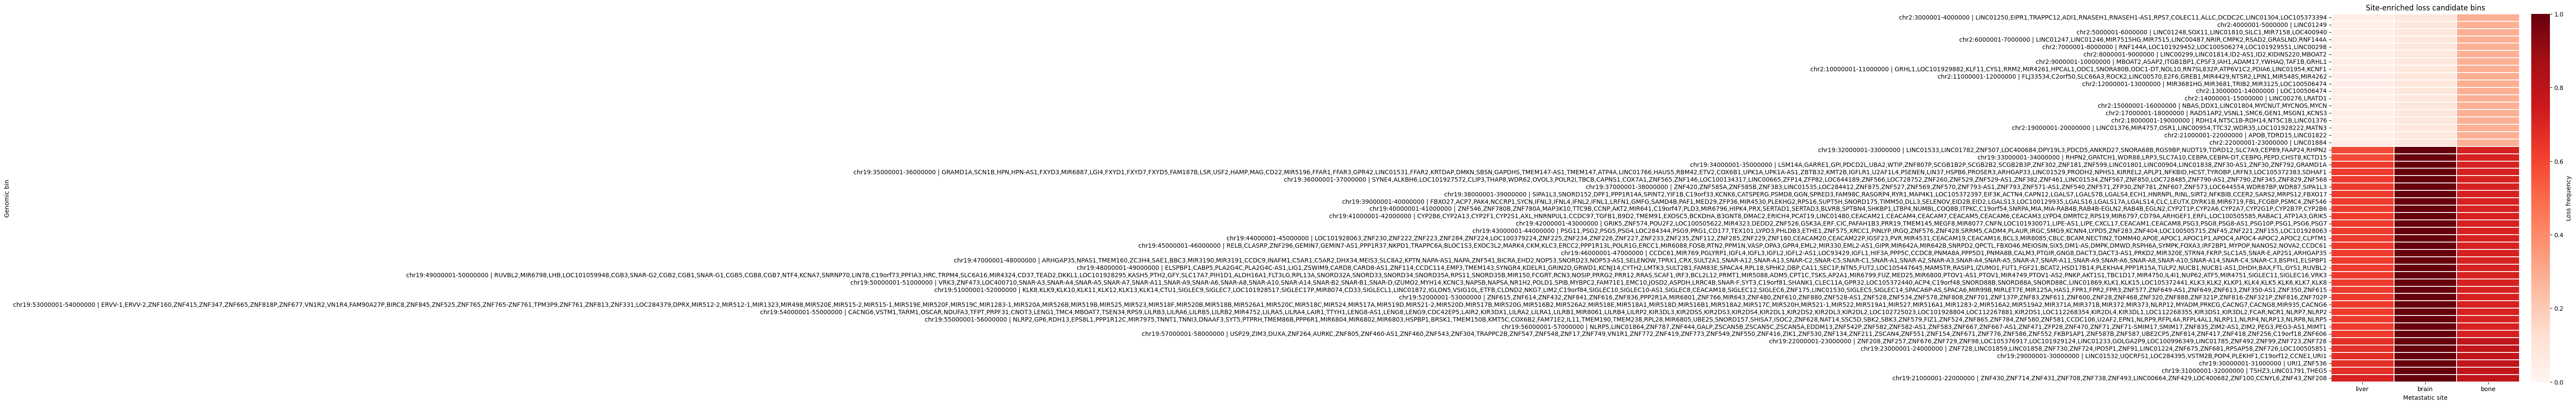

/ihome/alee/rak373/.conda/envs/RegionalFragmentAnalysis/lib/python3.7/site-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)


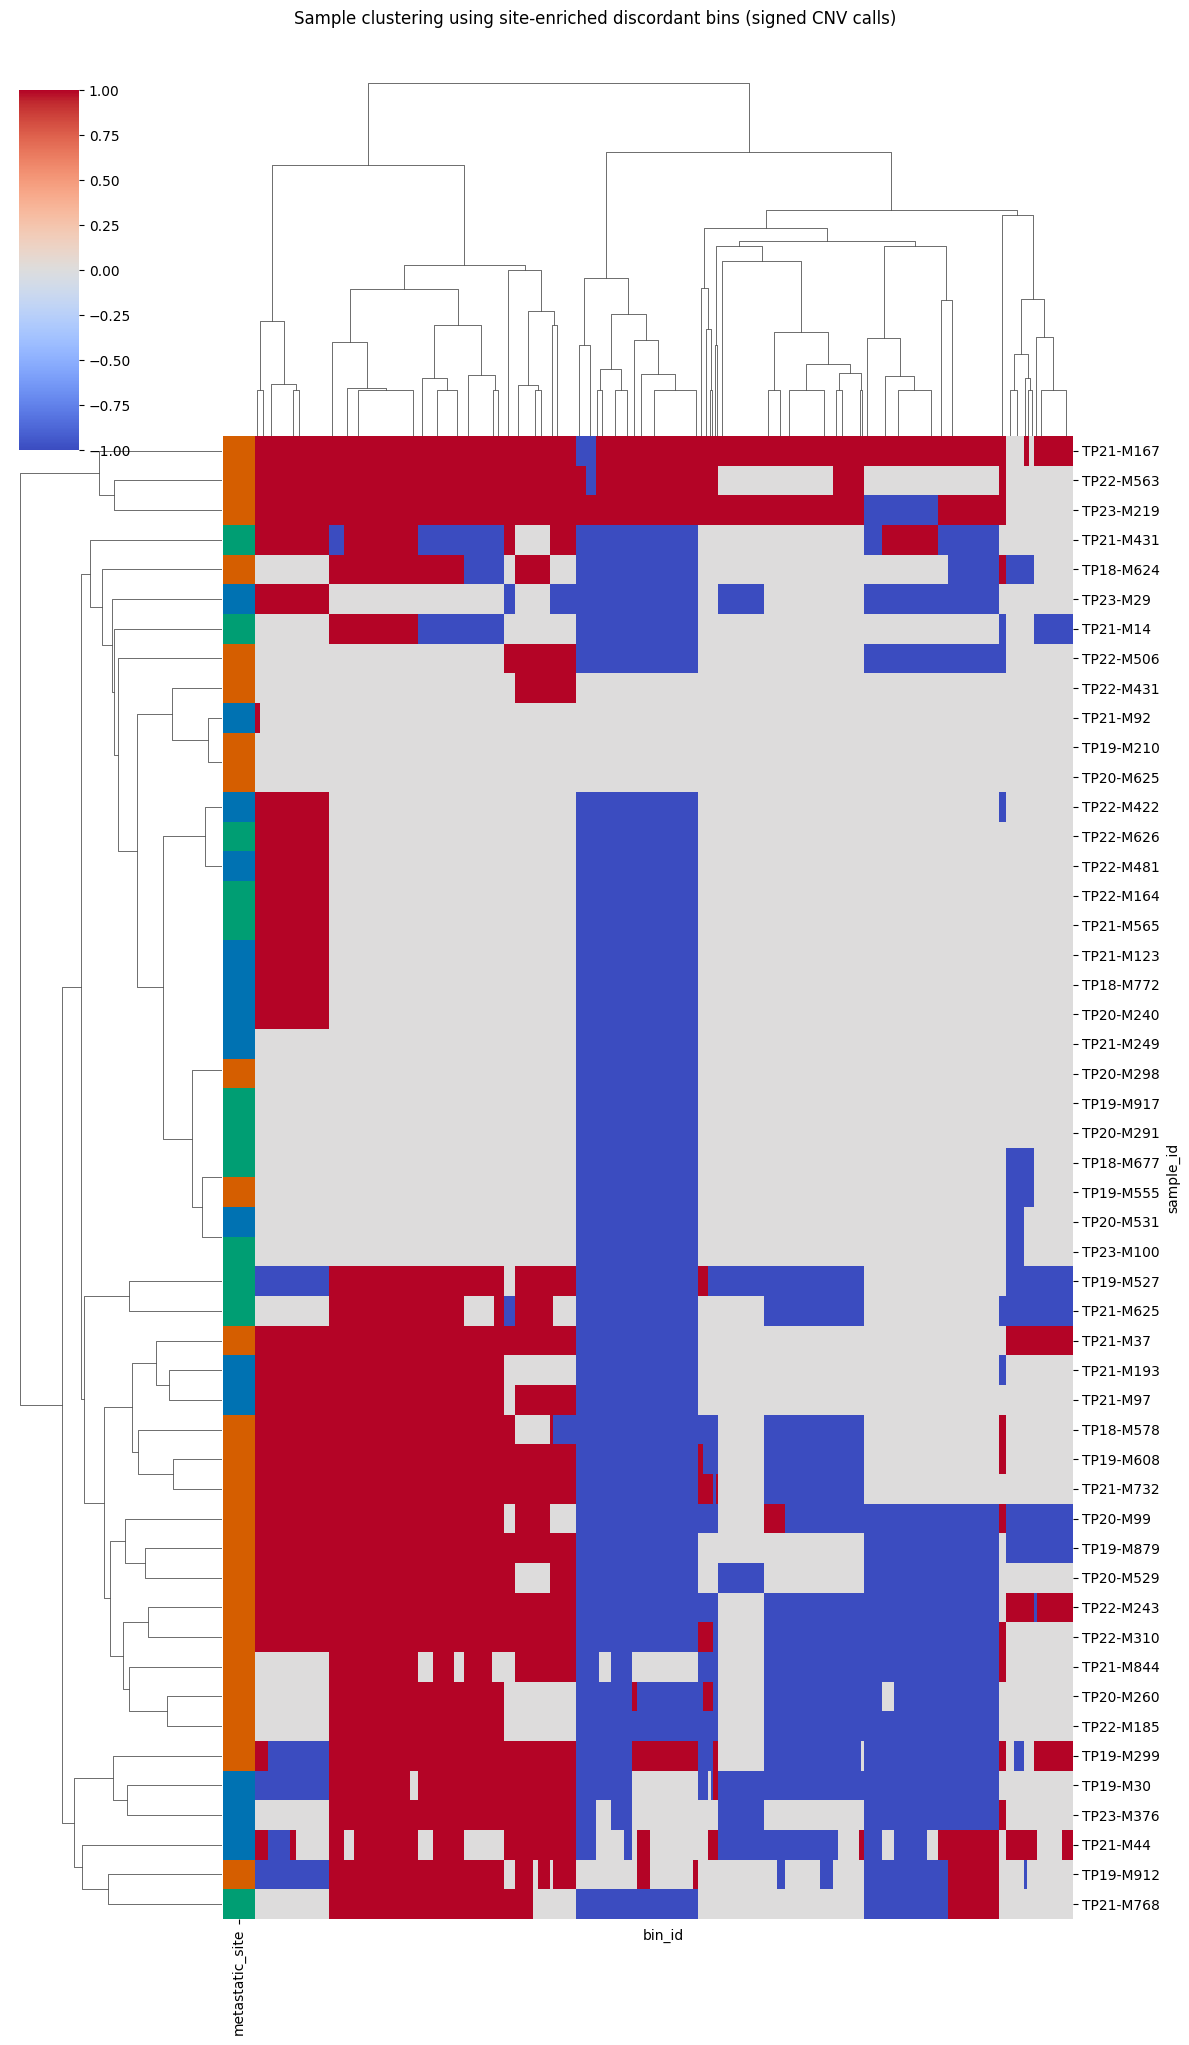

/ihome/alee/rak373/.conda/envs/RegionalFragmentAnalysis/lib/python3.7/site-packages/seaborn/matrix.py:560: UserWarning: Clustering large matrix with scipy. Installing `fastcluster` may give better performance.
  warnings.warn(msg)


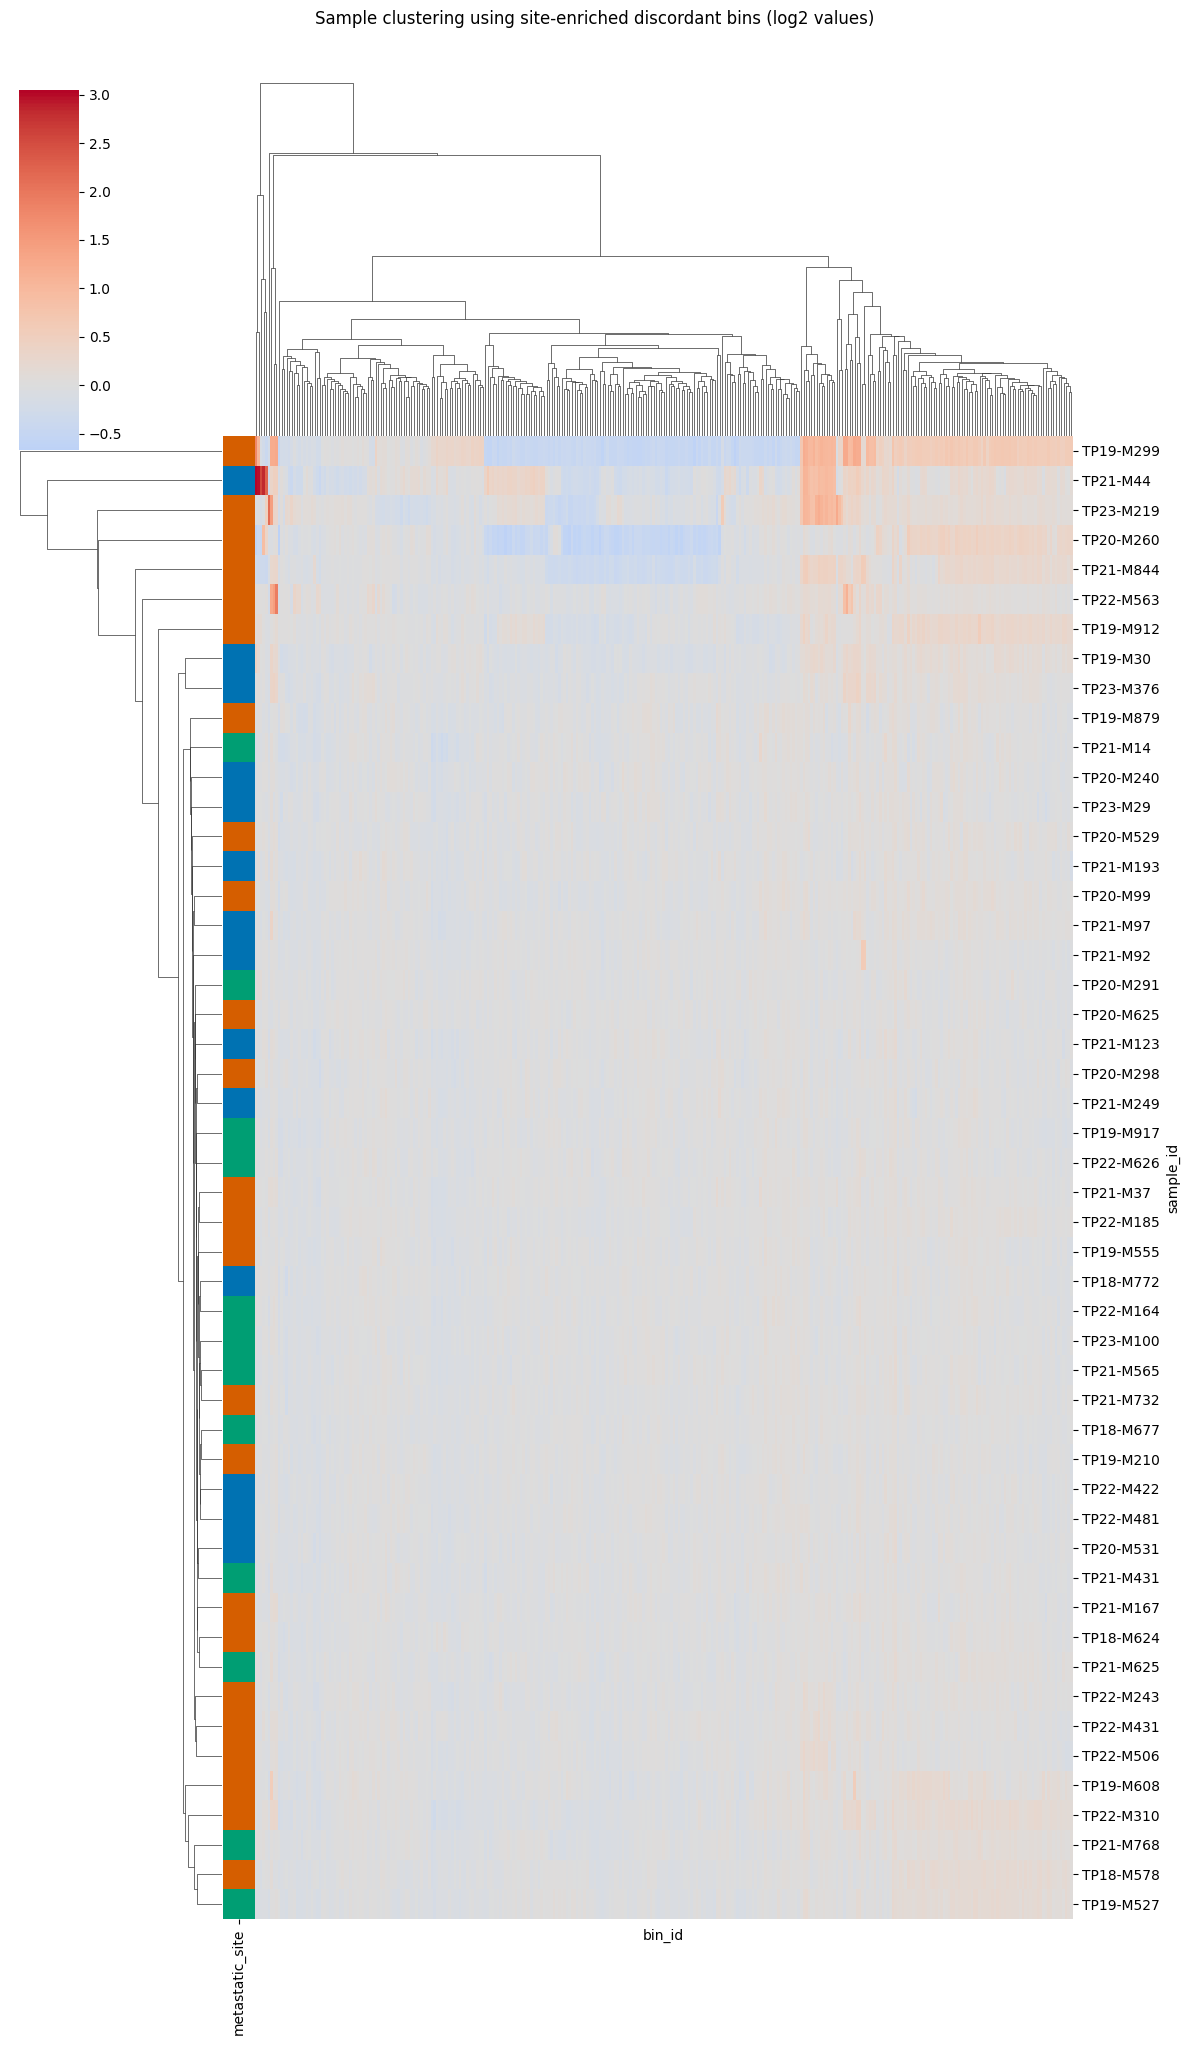

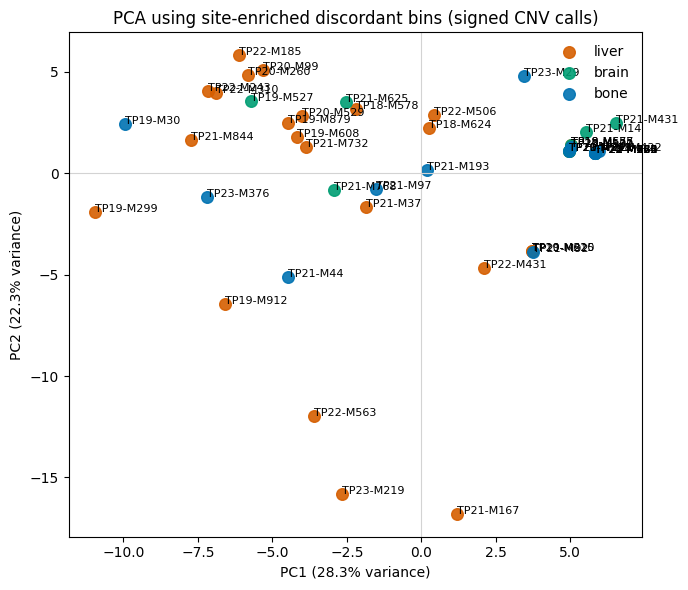

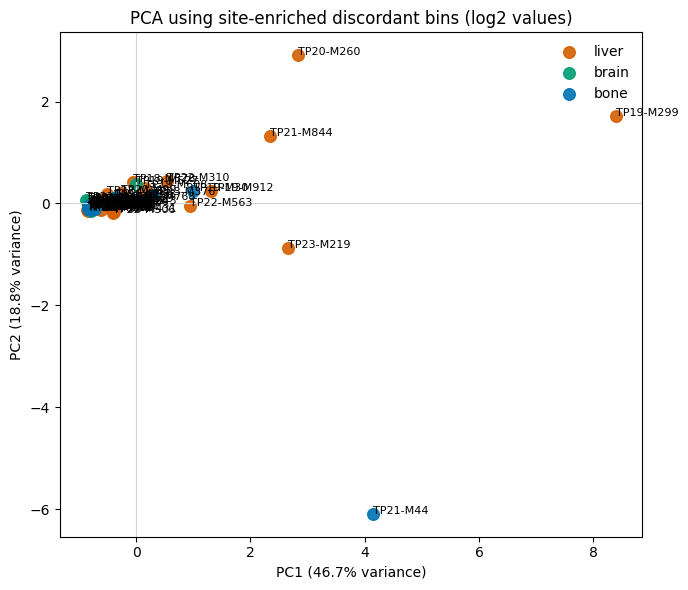


================ Discordant-bin analysis summary ================
Gain discordant bins: 2587
Loss discordant bins: 2318
Gain site-enriched candidates: 129
Loss site-enriched candidates: 192
Combined unique candidate bins: 321

Sample x bin matrix shapes:
Signed call matrix: (50, 321)
Log2 matrix: (50, 321)

Output directory:
/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/CNV_Profiles/metastasis_single_site_one_per_bios_site/Discordant_bin_analysis


In [7]:
# ============================================================
# PURPOSE OF THIS ANALYSIS
# ============================================================
# This script is designed to identify genomic bins whose CNV
# gain/loss frequencies differ across the top 3 metastatic sites
# (liver, brain, and bone), with the goal of finding candidate
# site-specific genomic regions.
# BIOLOGICAL RATIONALE
# Although genome-wide CNV patterns correlated
# across metastatic sites, some genomic bins may deviate from the
# shared background pattern. These discordant/site-enriched bins
# may reflect organ-specific metastatic selection and therefore
# represent biologically meaningful candidate regions.

# ============================================================
# Discordant-bin / site-enriched-bin analysis
# ============================================================
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from itertools import combinations

DISCORD_OUTDIR = os.path.join(OUTDIR, "Discordant_bin_analysis")
os.makedirs(DISCORD_OUTDIR, exist_ok=True)

# -----------------------------
# Thresholds
# -----------------------------
MIN_EVENT_FREQ = 0.05   # keep bins where at least one site has >= 5% freq
MIN_RANGE = 0.20        # max(site freq) - min(site freq) >= 0.20
MIN_TOP_FREQ = 0.20     # top site must have at least 20% freq
TOP_N_HEATMAP = 50
TOP_N_PER_SITE = 100    # candidate bins per site per mode

# ------------------------------------------------------------
# Helpers
# ------------------------------------------------------------
def make_bin_id(df):
    return (
        df["chromosome"].astype(str) + ":" +
        df["start"].astype(int).astype(str) + "-" +
        df["end"].astype(int).astype(str)
    )

def add_gene_label(df):
    gene = df["gene"].fillna("").astype(str).str.strip()
    return np.where(gene.eq("") | gene.eq("nan"), df["bin_id"], df["bin_id"] + " | " + gene)

def identify_discordant_bins(plot_df, mode="gain", site_order=None, min_event_freq=0.05):
    """
    For each genomic bin, quantify how different the frequencies are across sites.
    mode = 'gain' or 'loss'
    """
    if site_order is None:
        site_order = SITE_ORDER

    freq_cols = [f"{site}_{mode}_freq" for site in site_order]

    df = plot_df[["chromosome", "start", "end", "gene"] + freq_cols].copy()
    df["bin_id"] = make_bin_id(df)

    # summary metrics
    df["max_freq"] = df[freq_cols].max(axis=1)
    df["min_freq"] = df[freq_cols].min(axis=1)
    df["mean_freq"] = df[freq_cols].mean(axis=1)
    df["sd_freq"] = df[freq_cols].std(axis=1)
    df["range_freq"] = df["max_freq"] - df["min_freq"]
    df["n_sites_nonzero"] = (df[freq_cols].fillna(0) > 0).sum(axis=1)

    # highest / lowest site
    df["highest_site"] = df[freq_cols].idxmax(axis=1).str.replace(f"_{mode}_freq", "", regex=False)
    df["lowest_site"]  = df[freq_cols].idxmin(axis=1).str.replace(f"_{mode}_freq", "", regex=False)

    # pairwise differences
    for s1, s2 in combinations(site_order, 2):
        c1 = f"{s1}_{mode}_freq"
        c2 = f"{s2}_{mode}_freq"
        df[f"{s1}_vs_{s2}_abs_diff"] = (df[c1] - df[c2]).abs()

    # keep informative bins only
    df = df[df["max_freq"] >= min_event_freq].copy()

    # sort by discordance
    df = df.sort_values(
        ["range_freq", "sd_freq", "max_freq"],
        ascending=[False, False, False]
    ).reset_index(drop=True)

    df["label"] = add_gene_label(df)
    return df


def select_site_enriched_bins(discord_df, mode="gain", site_order=None,
                              min_range=0.20, min_top_freq=0.20, top_n_per_site=100):
    """
    Select bins most enriched in one site relative to the others.
    """
    if site_order is None:
        site_order = SITE_ORDER

    freq_cols = [f"{site}_{mode}_freq" for site in site_order]

    df = discord_df.copy()
    df = df[(df["range_freq"] >= min_range) & (df["max_freq"] >= min_top_freq)].copy()

    out = []
    for site in site_order:
        site_col = f"{site}_{mode}_freq"
        other_cols = [c for c in freq_cols if c != site_col]

        sub = df[df["highest_site"] == site].copy()
        if sub.empty:
            continue

        # how much the top site exceeds the next-highest site
        sub["site_advantage"] = sub[site_col] - sub[other_cols].max(axis=1)
        sub["enriched_site"] = site
        sub["mode"] = mode

        sub = sub.sort_values(
            ["site_advantage", "range_freq", "max_freq"],
            ascending=[False, False, False]
        ).head(top_n_per_site)

        out.append(sub)

    if len(out) == 0:
        empty = discord_df.iloc[0:0].copy()
        empty["site_advantage"] = np.nan
        empty["enriched_site"] = ""
        empty["mode"] = mode
        return empty

    out = pd.concat(out, ignore_index=True)
    out = out.sort_values(
        ["enriched_site", "site_advantage", "range_freq", "max_freq"],
        ascending=[True, False, False, False]
    ).reset_index(drop=True)

    return out


def plot_frequency_heatmap(df, mode="gain", top_n=50, outprefix="heatmap", site_order=None, title=None):
    """
    Heatmap of site frequencies for top discordant / enriched bins.
    """
    if site_order is None:
        site_order = SITE_ORDER

    freq_cols = [f"{site}_{mode}_freq" for site in site_order]

    if df.empty:
        print(f"[WARN] No bins to plot for {mode}: {outprefix}")
        return

    temp = df.head(top_n).copy()
    heat = temp[freq_cols].copy()
    heat.columns = site_order
    heat.index = temp["label"]

    plt.figure(figsize=(7, max(6, top_n * 0.22)))
    sns.heatmap(
        heat,
        cmap="Reds",
        vmin=0,
        vmax=1,
        linewidths=0.3,
        linecolor="white",
        cbar_kws={"label": f"{mode.capitalize()} frequency"}
    )
    plt.xlabel("Metastatic site")
    plt.ylabel("Genomic bin")
    if title is None:
        title = f"Top {top_n} discordant bins by {mode} frequency"
    plt.title(title)
    plt.tight_layout()
    plt.savefig(f"{outprefix}.png", dpi=300, bbox_inches="tight")
    plt.savefig(f"{outprefix}.pdf", bbox_inches="tight")
    plt.show()
    plt.close()


def build_sample_feature_matrix(wide, candidate_bins, samples, value_type="call"):
    """
    Build sample x bin matrix for downstream PCA / clustering / classification.
    value_type:
      - 'call' -> signed CNV call: GAIN=1, NEUTRAL=0, LOSS=-1
      - 'log2' -> sample log2 value per bin
    """
    if candidate_bins.empty:
        return pd.DataFrame()

    key = wide[["chromosome", "start", "end"]].copy()
    key["chromosome"] = key["chromosome"].astype(str)
    key["start"] = pd.to_numeric(key["start"], errors="coerce")
    key["end"] = pd.to_numeric(key["end"], errors="coerce")
    key = key.dropna(subset=["chromosome", "start", "end"]).copy()
    key["start"] = key["start"].astype(int)
    key["end"] = key["end"].astype(int)
    key["bin_id"] = make_bin_id(key)

    cand = candidate_bins[["chromosome", "start", "end"]].drop_duplicates().copy()
    cand["chromosome"] = cand["chromosome"].astype(str)
    cand["start"] = pd.to_numeric(cand["start"], errors="coerce").astype(int)
    cand["end"] = pd.to_numeric(cand["end"], errors="coerce").astype(int)
    cand["bin_id"] = make_bin_id(cand)

    keep_bin_ids = set(cand["bin_id"])
    row_mask = key["bin_id"].isin(keep_bin_ids)

    row_info = key.loc[row_mask, ["bin_id"]].copy()
    row_info = row_info.reset_index().rename(columns={"index": "wide_row_index"})

    if row_info.empty:
        return pd.DataFrame()

    def call_to_signed(x):
        x = clean_call(x)
        if x == "GAIN":
            return 1
        if x == "LOSS":
            return -1
        if x == "NEUTRAL":
            return 0
        return np.nan

    value_dict = {}
    for sample in samples:
        if value_type == "call":
            col = f"{sample}.Corrected_Call"
            if col not in wide.columns:
                continue
            vals = wide.loc[row_info["wide_row_index"], col].apply(call_to_signed).to_numpy()

        elif value_type == "log2":
            col = f"{sample}.log2"
            if col not in wide.columns:
                continue
            vals = pd.to_numeric(wide.loc[row_info["wide_row_index"], col], errors="coerce").to_numpy()

        else:
            raise ValueError("value_type must be 'call' or 'log2'")

        value_dict[sample] = vals

    if len(value_dict) == 0:
        return pd.DataFrame()

    mat = pd.DataFrame(value_dict, index=row_info["bin_id"]).T
    mat.index.name = "sample_id"
    mat.columns.name = "bin_id"

    # Keep columns in candidate-bin order
    ordered_cols = [b for b in cand["bin_id"].tolist() if b in mat.columns]
    mat = mat.loc[:, ordered_cols]

    return mat


def save_matrix_with_metadata(mat, sample_to_site, outprefix):
    """
    Save sample x bin matrix plus sample metadata.
    """
    if mat.empty:
        print(f"[WARN] Empty matrix: {outprefix}")
        return pd.DataFrame()

    sample_meta = pd.DataFrame({
        "sample_id": mat.index,
        "metastatic_site": [sample_to_site.get(s, "NA") for s in mat.index]
    })

    mat.to_csv(f"{outprefix}.matrix.tsv", sep="\t")
    sample_meta.to_csv(f"{outprefix}.sample_metadata.tsv", sep="\t", index=False)

    return sample_meta


def plot_sample_clustermap(mat, sample_meta, outprefix, title):
    """
    Hierarchical clustering heatmap of samples using selected bins.
    """
    if mat.empty or mat.shape[0] < 2 or mat.shape[1] < 2:
        print(f"[WARN] Not enough data for clustermap: {outprefix}")
        return

    row_colors = sample_meta.set_index("sample_id").loc[mat.index, "metastatic_site"].map(SITE_COLORS)

    g = sns.clustermap(
        mat.fillna(0),
        cmap="coolwarm",
        center=0,
        row_colors=row_colors,
        xticklabels=False,
        yticklabels=True,
        linewidths=0,
        figsize=(12, max(5, mat.shape[0] * 0.40))
    )
    g.fig.suptitle(title, y=1.02)
    g.savefig(f"{outprefix}.png", dpi=300, bbox_inches="tight")
    g.savefig(f"{outprefix}.pdf", bbox_inches="tight")
    plt.show()
    plt.close()


def run_simple_pca(mat):
    """
    PCA using numpy SVD only (no sklearn required).
    Returns sample scores and explained variance ratio.
    """
    if mat.empty or mat.shape[0] < 2 or mat.shape[1] < 2:
        return None, None

    X = mat.fillna(0).copy()

    # remove zero-variance bins
    keep = X.var(axis=0) > 0
    X = X.loc[:, keep]

    if X.shape[1] < 2:
        return None, None

    # center columns
    Xc = X - X.mean(axis=0)

    U, S, Vt = np.linalg.svd(Xc.values, full_matrices=False)
    scores = U[:, :2] * S[:2]

    var = (S ** 2)
    evr = var / var.sum()

    pca_df = pd.DataFrame({
        "sample_id": X.index,
        "PC1": scores[:, 0],
        "PC2": scores[:, 1]
    })

    return pca_df, evr[:2]


def plot_pca(pca_df, evr, sample_to_site, outprefix, title):
    """
    PCA scatter plot colored by metastatic site.
    """
    if pca_df is None or evr is None or pca_df.empty:
        print(f"[WARN] PCA not generated: {outprefix}")
        return

    pca_df = pca_df.copy()
    pca_df["metastatic_site"] = pca_df["sample_id"].map(sample_to_site)

    plt.figure(figsize=(7, 6))
    for site in SITE_ORDER:
        sub = pca_df[pca_df["metastatic_site"] == site]
        if sub.empty:
            continue

        plt.scatter(
            sub["PC1"],
            sub["PC2"],
            s=70,
            color=SITE_COLORS[site],
            label=site,
            alpha=0.9
        )

        for _, row in sub.iterrows():
            plt.text(row["PC1"], row["PC2"], row["sample_id"], fontsize=8)

    plt.axhline(0, color="lightgrey", linewidth=0.8)
    plt.axvline(0, color="lightgrey", linewidth=0.8)
    plt.xlabel(f"PC1 ({evr[0] * 100:.1f}% variance)")
    plt.ylabel(f"PC2 ({evr[1] * 100:.1f}% variance)")
    plt.title(title)
    plt.legend(frameon=False)
    plt.tight_layout()
    plt.savefig(f"{outprefix}.png", dpi=300, bbox_inches="tight")
    plt.savefig(f"{outprefix}.pdf", bbox_inches="tight")
    plt.show()
    plt.close()


# ------------------------------------------------------------
# 1) Identify discordant bins
# ------------------------------------------------------------
gain_discord = identify_discordant_bins(
    plot_df,
    mode="gain",
    site_order=SITE_ORDER,
    min_event_freq=MIN_EVENT_FREQ
)

loss_discord = identify_discordant_bins(
    plot_df,
    mode="loss",
    site_order=SITE_ORDER,
    min_event_freq=MIN_EVENT_FREQ
)

gain_discord.to_csv(
    os.path.join(DISCORD_OUTDIR, "gain_discordant_bins.all.tsv"),
    sep="\t", index=False
)

loss_discord.to_csv(
    os.path.join(DISCORD_OUTDIR, "loss_discordant_bins.all.tsv"),
    sep="\t", index=False
)

# ------------------------------------------------------------
# 2) Select site-enriched candidate bins
# ------------------------------------------------------------
gain_candidates = select_site_enriched_bins(
    gain_discord,
    mode="gain",
    site_order=SITE_ORDER,
    min_range=MIN_RANGE,
    min_top_freq=MIN_TOP_FREQ,
    top_n_per_site=TOP_N_PER_SITE
)

loss_candidates = select_site_enriched_bins(
    loss_discord,
    mode="loss",
    site_order=SITE_ORDER,
    min_range=MIN_RANGE,
    min_top_freq=MIN_TOP_FREQ,
    top_n_per_site=TOP_N_PER_SITE
)

gain_candidates.to_csv(
    os.path.join(DISCORD_OUTDIR, "gain_site_enriched_candidates.tsv"),
    sep="\t", index=False
)

loss_candidates.to_csv(
    os.path.join(DISCORD_OUTDIR, "loss_site_enriched_candidates.tsv"),
    sep="\t", index=False
)

# Combined candidate table
combined_candidates = pd.concat(
    [gain_candidates, loss_candidates],
    ignore_index=True
)

combined_candidates.to_csv(
    os.path.join(DISCORD_OUTDIR, "combined_gain_loss_site_enriched_candidates.tsv"),
    sep="\t", index=False
)

combined_bins_unique = combined_candidates[["chromosome", "start", "end", "gene"]].drop_duplicates().copy()
combined_bins_unique["bin_id"] = make_bin_id(combined_bins_unique)

combined_bins_unique.to_csv(
    os.path.join(DISCORD_OUTDIR, "combined_unique_candidate_bins.tsv"),
    sep="\t", index=False
)

# ------------------------------------------------------------
# 3) Heatmaps
# ------------------------------------------------------------
plot_frequency_heatmap(
    gain_discord,
    mode="gain",
    top_n=TOP_N_HEATMAP,
    outprefix=os.path.join(DISCORD_OUTDIR, "top_gain_discordant_bins"),
    title=f"Top {TOP_N_HEATMAP} discordant bins by gain frequency"
)

plot_frequency_heatmap(
    loss_discord,
    mode="loss",
    top_n=TOP_N_HEATMAP,
    outprefix=os.path.join(DISCORD_OUTDIR, "top_loss_discordant_bins"),
    title=f"Top {TOP_N_HEATMAP} discordant bins by loss frequency"
)

plot_frequency_heatmap(
    gain_candidates,
    mode="gain",
    top_n=min(TOP_N_HEATMAP, len(gain_candidates)),
    outprefix=os.path.join(DISCORD_OUTDIR, "gain_site_enriched_candidates_heatmap"),
    title="Site-enriched gain candidate bins"
)

plot_frequency_heatmap(
    loss_candidates,
    mode="loss",
    top_n=min(TOP_N_HEATMAP, len(loss_candidates)),
    outprefix=os.path.join(DISCORD_OUTDIR, "loss_site_enriched_candidates_heatmap"),
    title="Site-enriched loss candidate bins"
)

# ------------------------------------------------------------
# 4) Sample x bin matrices for PCA / clustering / classification
# ------------------------------------------------------------
# Signed CNV call matrix: GAIN=1, NEUTRAL=0, LOSS=-1
candidate_call_matrix = build_sample_feature_matrix(
    wide,
    combined_bins_unique,
    samples=samples,
    value_type="call"
)

call_meta = save_matrix_with_metadata(
    candidate_call_matrix,
    sample_to_site,
    os.path.join(DISCORD_OUTDIR, "combined_candidate_bins_signed_call")
)

# Raw log2 matrix
candidate_log2_matrix = build_sample_feature_matrix(
    wide,
    combined_bins_unique,
    samples=samples,
    value_type="log2"
)

log2_meta = save_matrix_with_metadata(
    candidate_log2_matrix,
    sample_to_site,
    os.path.join(DISCORD_OUTDIR, "combined_candidate_bins_log2")
)

# ------------------------------------------------------------
# 5) Clustering
# ------------------------------------------------------------
plot_sample_clustermap(
    candidate_call_matrix,
    call_meta,
    outprefix=os.path.join(DISCORD_OUTDIR, "combined_candidate_bins_signed_call_clustermap"),
    title="Sample clustering using site-enriched discordant bins (signed CNV calls)"
)

plot_sample_clustermap(
    candidate_log2_matrix,
    log2_meta,
    outprefix=os.path.join(DISCORD_OUTDIR, "combined_candidate_bins_log2_clustermap"),
    title="Sample clustering using site-enriched discordant bins (log2 values)"
)

# ------------------------------------------------------------
# 6) PCA
# ------------------------------------------------------------
pca_call_df, pca_call_evr = run_simple_pca(candidate_call_matrix)
plot_pca(
    pca_call_df,
    pca_call_evr,
    sample_to_site,
    outprefix=os.path.join(DISCORD_OUTDIR, "combined_candidate_bins_signed_call_PCA"),
    title="PCA using site-enriched discordant bins (signed CNV calls)"
)

pca_log2_df, pca_log2_evr = run_simple_pca(candidate_log2_matrix)
plot_pca(
    pca_log2_df,
    pca_log2_evr,
    sample_to_site,
    outprefix=os.path.join(DISCORD_OUTDIR, "combined_candidate_bins_log2_PCA"),
    title="PCA using site-enriched discordant bins (log2 values)"
)

# ------------------------------------------------------------
# 7) Per-site top tables for quick review
# ------------------------------------------------------------
for mode, cand_df in [("gain", gain_candidates), ("loss", loss_candidates)]:
    for site in SITE_ORDER:
        sub = cand_df[cand_df["enriched_site"] == site].copy()
        sub.to_csv(
            os.path.join(DISCORD_OUTDIR, f"{mode}_{site}_site_enriched_candidates.tsv"),
            sep="\t", index=False
        )

# ------------------------------------------------------------
# 8) Summary printout
# ------------------------------------------------------------
print("\n================ Discordant-bin analysis summary ================")
print("Gain discordant bins:", gain_discord.shape[0])
print("Loss discordant bins:", loss_discord.shape[0])
print("Gain site-enriched candidates:", gain_candidates.shape[0])
print("Loss site-enriched candidates:", loss_candidates.shape[0])
print("Combined unique candidate bins:", combined_bins_unique.shape[0])

print("\nSample x bin matrix shapes:")
print("Signed call matrix:", candidate_call_matrix.shape)
print("Log2 matrix:", candidate_log2_matrix.shape)

print("\nOutput directory:")
print(DISCORD_OUTDIR)